# 02 · Limpieza y EDA

*Lo primero es separar train y test por disco, antes de mirar ningún dato. Así, las decisiones de limpieza (qué columnas quito, cómo trato los missings) las tomo solo con train, y el test se queda como datos que el modelo no ha visto nunca.*

*Después aplico a test y a abril las mismas transformaciones, ya decididas con train: no miro sus datos para decidir nada, solo les doy el formato que el modelo sabe leer. Abril es mi prueba final: un mes posterior, con discos que no salen en enero ni febrero, para ver si el modelo aguanta en el futuro.*

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.model_selection import train_test_split

import bootcampviztools as bt


if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

colores = {0: "#00708A", 1: "#8E1F4B"}
target = "falla_30d"
df = pd.read_csv("data/processed/01_dataset_unido.csv", low_memory = False)
df.shape

(25993, 123)

## Separación train / test por disco

*Un mismo disco puede aparecer hasta en 9 fechas. Si unas filas suyas fueran a train y otras a test, el modelo "reconocería" el disco y el resultado saldría inflado. Por eso reparto discos, no filas: el 80 % a train y el 20 % a test, con la misma proporción de discos que fallan en los dos.*

In [2]:
# Split por disco ANTES de mirar nada: cada disco va entero a train o a test
falla_disco = df.groupby("serial_number")[target].max()
discos_train, discos_test = train_test_split(list(falla_disco.index), test_size = 0.2,
                                             stratify = falla_disco.values, random_state = 42)
train_set = df[df["serial_number"].isin(discos_train)]
test_set = df[df["serial_number"].isin(discos_test)]

print("Train:", train_set.shape, "| % fallos:", round(train_set[target].mean() * 100, 1))
print("Test:", test_set.shape, "| % fallos:", round(test_set[target].mean() * 100, 1))
print("Discos en train y test a la vez:", len(set(train_set["serial_number"]) & set(test_set["serial_number"])))
filas_por_disco = df.groupby("serial_number").size()
print("Discos distintos:", len(filas_por_disco), "| discos que aparecen en más de una fecha:", (filas_por_disco > 1).sum())

Train: (20812, 123) | % fallos: 10.7
Test: (5181, 123) | % fallos: 10.4
Discos en train y test a la vez: 0
Discos distintos: 23381 | discos que aparecen en más de una fecha: 1455


## Missings por atributo SMART

*Cada fabricante reporta los atributos SMART que quiere, así que hay columnas casi vacías. Lo miro solo en train. Si una columna tiene más del 50 % de missings, la elimino: rellenarla sería inventarme más de la mitad de los datos.*

smart_183_raw    99.8
smart_189_raw    93.8
smart_184_raw    93.3
smart_190_raw    66.3
smart_188_raw    66.0
smart_187_raw    66.0
smart_242_raw    55.4
smart_241_raw    55.4
smart_240_raw    35.3
smart_197_raw     2.6
dtype: float64

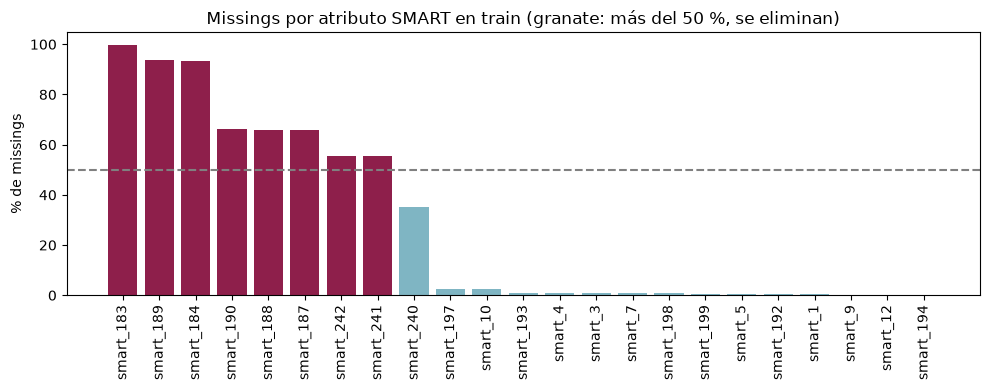

In [3]:
smart_raw = [c for c in train_set.columns if c.startswith("smart_") and c.endswith("_raw")]
missings = train_set[smart_raw].isna().mean().sort_values(ascending = False) * 100

plt.figure(figsize = (10, 4))
plt.bar(missings.index.str.replace("_raw", ""), missings.values,
        color = ["#8E1F4B" if v > 50 else "#7FB5C3" for v in missings.values])
plt.axhline(50, color = "grey", linestyle = "--")
plt.ylabel("% de missings")
plt.title("Missings por atributo SMART en train (granate: más del 50 %, se eliminan)")
plt.xticks(rotation = 90)
plt.tight_layout()
missings.round(1).head(10)

## ¿Por qué faltan smart_187 y smart_188?

*El 66 % de missings en 187 y 188 me hizo sospechar que no faltan al azar. Compruebo en train qué fabricante los reporta. Para eso saco la marca del modelo del disco: los Seagate empiezan por "ST" y no llevan el nombre delante.*

In [4]:
FABRICANTES = ["TOSHIBA", "Seagate", "WDC", "HGST"]

def poner_fabricante(modelo):
    modelo = str(modelo)
    if " " in modelo:
        marca = modelo.split(" ")[0]
    else:
        marca = modelo[:2]          # los Seagate empiezan por ST sin la marca delante
    if marca == "ST":
        marca = "Seagate"
    if marca not in FABRICANTES:
        marca = "Otros"
    return marca

fabricante_train = train_set["model"].apply(poner_fabricante).rename("fabricante")
train_set[["smart_187_raw", "smart_188_raw"]].isna().groupby(fabricante_train).mean().mul(100).round(1)

,smart_187_raw,smart_188_raw
fabricante,,
HGST,100.0,100.0
Otros,56.9,62.3
Seagate,1.5,1.5
TOSHIBA,100.0,100.0
WDC,99.8,99.8


*Conclusión: 187 y 188 solo los reporta Seagate. Para HGST, Toshiba y WDC faltan siempre, así que rellenarlos sería inventar datos de marcas que no los miden. Los elimino junto con el resto de columnas que pasan del 50 %.*

## Limpieza y nuevas variables

*Junto toda la limpieza en una función, `limpiar()`, y la aplico por separado a train, test y abril. La función no aprende nada de los datos: quita columnas que ya decidí con train y calcula variables fila a fila, con los datos de cada disco.*

*Las columnas con más del 50 % de missings en train salen fuera. De las que quedan, descarto smart_10 (casi siempre vale 0) y smart_240 (horas de vuelo del cabezal, repite lo que ya dice smart_9). Creo variables nuevas: fabricante, capacidad en TB, si el disco es nuevo y 31 tendencias. Cada tendencia mide cuánto ha subido un contador en los últimos 7, 14 o 30 días, porque un contador de errores que crece dice más que su valor del día.*

In [5]:
# Columnas a eliminar: las que pasan del 50 % de missings en train (gráfico de arriba)
SMART_ELIMINAR = [int(c.split("_")[1]) for c in missings[missings > 50].index]
print("Se eliminan:", sorted(SMART_ELIMINAR))

SMART_USAR = [1, 3, 4, 5, 7, 9, 12, 192, 193, 194, 197, 198, 199]
SMART_DELTA = [1, 4, 5, 7, 9, 12, 192, 193, 197, 198, 199]
SMART_DELTA_CORTO = [1, 4, 5, 7, 12, 192, 193, 197, 198, 199]

def limpiar(df):
    df = df.copy()
    smart_raw = [c for c in df.columns if c.startswith("smart_") and c.endswith("_raw")]
    df = df[~df[smart_raw].isna().all(axis = 1)]          # discos que no reportaron nada ese día

    quitar = [c for c in df.columns if c.endswith("_normalized")]
    for n in SMART_ELIMINAR + [10]:
        for sufijo in ["_raw", "_raw_hace7", "_raw_hace14", "_raw_hace30"]:
            if "smart_" + str(n) + sufijo in df.columns:
                quitar.append("smart_" + str(n) + sufijo)
    df = df.drop(columns = quitar)

    # Feature engineering
    df["fabricante"] = df["model"].apply(poner_fabricante)
    df["capacidad_tb"] = df["capacity_bytes"] / 1e12
    hace30 = ["smart_" + str(n) + "_raw_hace30" for n in SMART_USAR]
    df["disco_nuevo"] = df[hace30].isna().all(axis = 1).astype(int)
    for n in SMART_DELTA:
        hoy = "smart_" + str(n) + "_raw"
        df["delta_" + str(n)] = (df[hoy] - df[hoy + "_hace30"].fillna(df[hoy])).clip(lower = 0)
    for d in [7, 14]:
        for n in SMART_DELTA_CORTO:
            hoy = "smart_" + str(n) + "_raw"
            df["delta" + str(d) + "_" + str(n)] = (df[hoy] - df[hoy + "_hace" + str(d)].fillna(df[hoy])).clip(lower = 0)
    return df

features_num = ["smart_" + str(n) + "_raw" for n in SMART_USAR]
features_num += ["delta_" + str(n) for n in SMART_DELTA]
features_num += ["delta" + str(d) + "_" + str(n) for d in [7, 14] for n in SMART_DELTA_CORTO]
features_num += ["capacidad_tb", "disco_nuevo"]
features_cat = ["fabricante", "datacenter"]
guardar = ["serial_number", "fecha_foto", "fecha_fallo", "model"] + features_num + features_cat + [target]

# La misma función, por separado, para train, test y abril (no aprende nada de los datos)
train_set = limpiar(train_set)[guardar]
test_set = limpiar(test_set)[guardar]
abril = limpiar(pd.read_csv("data/processed/01_abril_unido.csv", low_memory = False))[guardar]
print("Train limpio:", train_set.shape, "| Test limpio:", test_set.shape, "| Abril limpio:", abril.shape)
print(len(features_num), "numéricas +", len(features_cat), "categóricas")
pd.crosstab(train_set["disco_nuevo"], train_set[target], normalize = "columns").round(3) * 100

Se eliminan: [183, 184, 187, 188, 189, 190, 241, 242]
Train limpio: (20760, 53) | Test limpio: (5163, 53) | Abril limpio: (4402, 53)
46 numéricas + 2 categóricas


falla_30d,0,1
disco_nuevo,,
0,99.1,96.7
1,0.9,3.3



*Se pierden unas pocas filas: discos que ese día no enviaron ninguna lectura. La tabla muestra algo interesante: entre los discos que fallan, un 3,3 % son nuevos (sin lectura de hace 30 días), frente al 0,9 % de los sanos. Que falte el historial también es información, y por eso lo guardo como variable.*

## Mini-EDA (I): cómo se reparte el target

*Antes de comparar variables miro cuántos discos fallan y cuántos no. Si las clases están muy descompensadas, la accuracy engaña: un modelo que dijera "ninguno falla" acertaría casi siempre y no serviría para nada.*

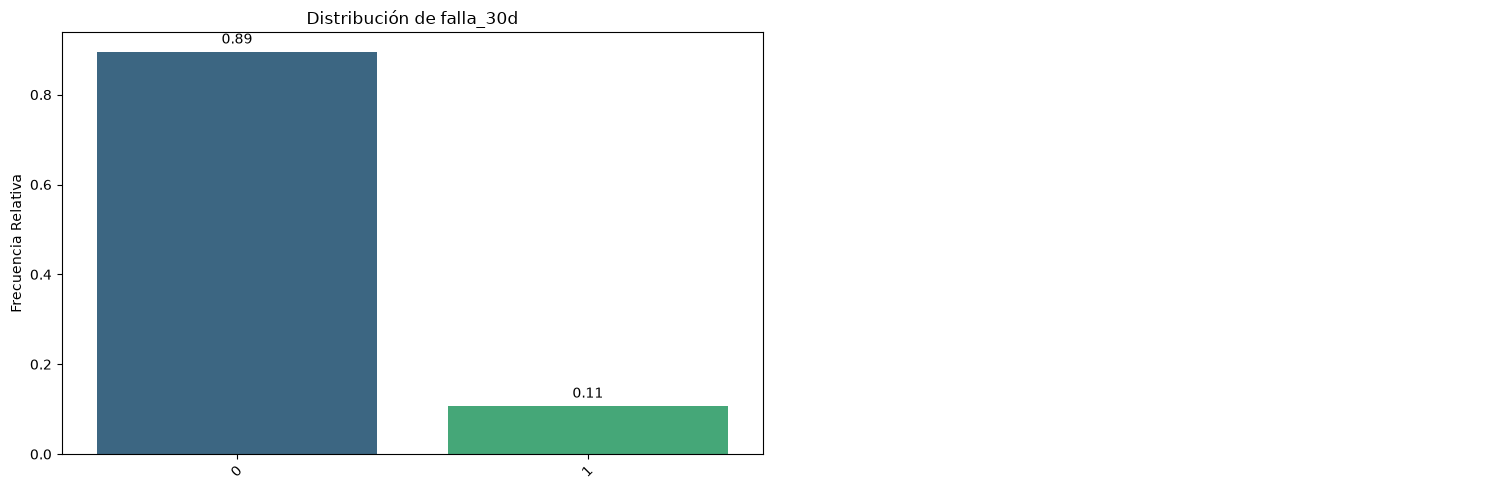

In [6]:
bt.pinta_distribucion_categoricas(train_set, [target], relativa = True, mostrar_valores = True)

*Un 89 % de sanos frente a un 11 % que falla: está desbalanceado. Por eso no mido con accuracy sino con PR-AUC, recall y precisión, y más adelante pruebo técnicas de balanceo.*

## Mini-EDA (II): variables frente al target

*Comparo los discos sanos con los que fallan en cuatro contadores clave. Uso Mann-Whitney y no la t de Student porque los SMART no siguen una normal: la mayoría vale 0 y unos pocos se disparan.*

In [7]:
claves = {"smart_5_raw": "Sectores reasignados", "smart_197_raw": "Sectores pendientes",
          "smart_198_raw": "Sectores incorregibles", "smart_9_raw": "Horas de uso"}
filas = []
for col, nombre in claves.items():
    sanos = train_set.loc[train_set[target] == 0, col].dropna()
    fallan = train_set.loc[train_set[target] == 1, col].dropna()
    p = mannwhitneyu(sanos, fallan).pvalue
    filas.append([nombre, round((sanos > 0).mean() * 100, 1), round((fallan > 0).mean() * 100, 1),
                  sanos.median(), fallan.median(), p])
pd.DataFrame(filas, columns = ["Variable", "% > 0 sanos", "% > 0 fallan", "Mediana sanos", "Mediana fallan", "p-valor"])

,Variable,% > 0 sanos,% > 0 fallan,Mediana sanos,Mediana fallan,p-valor
0,Sectores reasignados,4.9,55.5,0.0,2.0,0.000000e+00
1,Sectores pendientes,2.0,51.3,0.0,1.0,0.000000e+00
2,Sectores incorregibles,1.4,34.2,0.0,0.0,0.000000e+00
3,Horas de uso,100.0,100.0,30133.0,39611.5,2.263782e-35


*Los contadores de sectores separan muchísimo: el 51 % de los discos que fallan tiene sectores pendientes, frente al 2 % de los sanos. El p-valor sale 0 porque es más pequeño de lo que el ordenador puede escribir. Las horas de uso también son significativas, pero las dos medianas no están tan lejos. Que una diferencia sea significativa no quiere decir que sea importante para predecir.*

## Mini-EDA (III): cómo se distribuyen

*Lo veo en boxplots. Uso log(1 + valor) porque los contadores son casi todos 0 y unos pocos llegan a miles; sin el logaritmo, la caja quedaría aplastada contra el suelo. El +1 evita el log(0).*

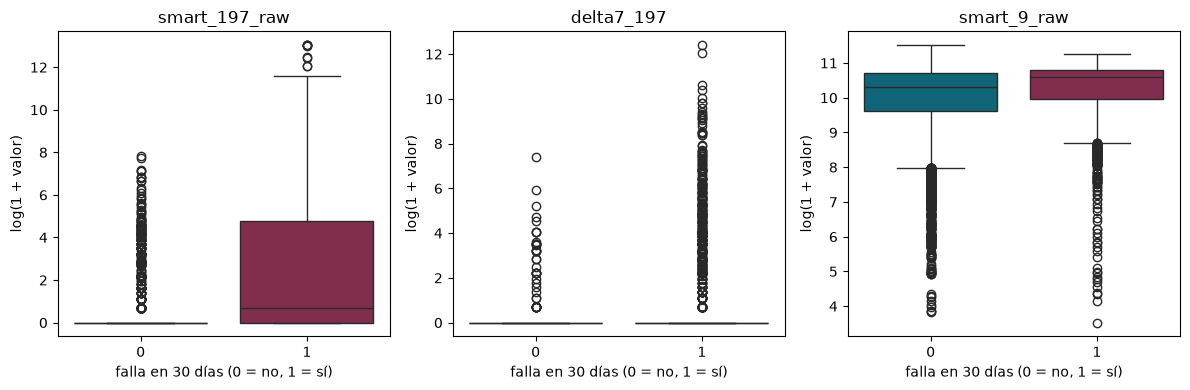

In [8]:
fig, ejes = plt.subplots(1, 3, figsize = (12, 4))
for eje, col in zip(ejes, ["smart_197_raw", "delta7_197", "smart_9_raw"]):
    sns.boxplot(data = train_set, x = target, y = np.log1p(train_set[col]), hue = target,
                palette = colores, legend = False, ax = eje)
    eje.set_title(col)
    eje.set_xlabel("falla en 30 días (0 = no, 1 = sí)")
    eje.set_ylabel("log(1 + valor)")
plt.tight_layout()

*Los sectores pendientes (197) y su subida en la última semana separan bien: en los sanos casi siempre valen 0. Las horas de uso se solapan mucho, lo mismo que decía la tabla de arriba: hay diferencia, pero pequeña.*

## Correlaciones: Pearson y Spearman

*Compruebo si hay variables que dicen lo mismo. Comparo Pearson con Spearman porque estos contadores tienen valores extremos, y Pearson se deja arrastrar por ellos. Para el mapa de calor uso las 15 variables del conjunto reducido, que serán las candidatas del modelo final.*

Pearson 192-193: 0.999
Spearman 192-193: 0.113


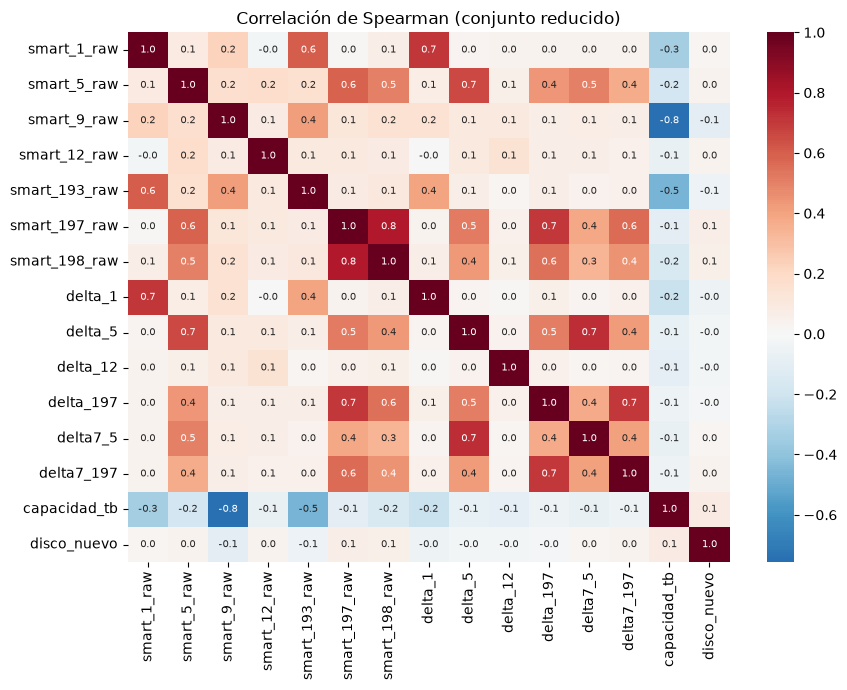

In [9]:
print("Pearson 192-193:", round(train_set["smart_192_raw"].corr(train_set["smart_193_raw"]), 3))
print("Spearman 192-193:", round(train_set["smart_192_raw"].corr(train_set["smart_193_raw"], method = "spearman"), 3))

reducido = ["smart_1_raw", "smart_5_raw", "smart_9_raw", "smart_12_raw", "smart_193_raw", "smart_197_raw",
            "smart_198_raw", "delta_1", "delta_5", "delta_12", "delta_197", "delta7_5", "delta7_197",
            "capacidad_tb", "disco_nuevo"]
plt.figure(figsize = (9, 7))
sns.heatmap(train_set[reducido].corr(method = "spearman"), cmap = "RdBu_r", center = 0, annot = True, fmt = ".1f",
            annot_kws = {"size": 7})
plt.title("Correlación de Spearman (conjunto reducido)")
plt.tight_layout()

*Pearson dice que 192 y 193 son casi la misma variable (0,999), pero Spearman la deja en 0,11: el 0,999 lo provocan unos pocos discos con valores enormes en los dos. Con contadores tan asimétricos me fío de Spearman.*

*En el mapa ningún par llega a 0,9. Los más fuertes son dos. Capacidad y horas de uso (−0,8): los discos grandes son los más modernos y llevan menos tiempo encendidos. Sectores pendientes e incorregibles (197 y 198, 0,8): los dos miden daño en la superficie del disco. Aun así, no dicen lo mismo: el 51 % de los que fallan tiene pendientes y solo el 34 % incorregibles. Cada contador se parece también a su propia subida (0,6-0,7), pero una cosa es cuántos errores hay y otra si están creciendo. Las mantengo todas.*

## Categóricas: el fabricante

*Compruebo si la marca está relacionada con fallar. Como las dos son categóricas, uso la prueba chi-cuadrado.*

In [10]:
tabla = pd.crosstab(train_set["fabricante"], train_set[target])
print("p-valor chi²:", chi2_contingency(tabla).pvalue)
(train_set.groupby("fabricante")[target].mean() * 100).round(1).sort_values(ascending = False)

p-valor chi²: 5.1549155919798e-60


fabricante
HGST       20.5
Seagate    11.8
Otros      10.8
TOSHIBA     9.8
WDC         6.5
Name: falla_30d, dtype: float64

*HGST falla un 20 % y WDC un 6,5 %, y la diferencia es significativa. Pero correlación no es causalidad: los HGST son los discos más viejos de la flota, así que buena parte de esa diferencia es edad, no marca. Dejo el fabricante como variable y el modelo decidirá cuánto pesa.*

## Conjuntos de variables y guardado

*Preparo tres conjuntos para compararlos en el siguiente notebook: todas las variables (46), sin las poco útiles (28) y un conjunto reducido sin redundantes (15). Las poco útiles son contadores que en train casi nunca cambian o casi no distinguen a los que fallan. Guardo train, test y abril por separado, y las listas de variables en un JSON para no copiarlas a mano.*

In [11]:
poco_utiles = ["smart_3_raw", "smart_7_raw", "smart_194_raw", "smart_199_raw", "delta_7", "delta_192",
               "delta_193", "delta_199", "delta7_7", "delta7_12", "delta7_192", "delta7_193", "delta7_199",
               "delta14_7", "delta14_12", "delta14_192", "delta14_193", "delta14_199"]
conjuntos = {"todas": features_num,
             "sin_poco_utiles": [c for c in features_num if c not in poco_utiles],
             "reducido": reducido}
for nombre, lista in conjuntos.items():
    print(nombre, len(lista), "variables")

with open("data/processed/conjuntos_variables.json", "w") as f:
    json.dump({"conjuntos": conjuntos, "categoricas": features_cat}, f, indent = 2)
pd.concat([train_set, test_set]).to_csv("data/processed/02_dataset_limpio.csv", index = False)
train_set.to_csv("data/train/train.csv", index = False)
test_set.to_csv("data/test/test.csv", index = False)
abril.to_csv("data/test/test_abril.csv", index = False)
print("Test de abril:", abril.shape, "| fallos:", abril[target].sum())

todas 46 variables
sin_poco_utiles 28 variables
reducido 15 variables
Test de abril: (4402, 53) | fallos: 467


*Comprobación: ningún disco está a la vez en train y en test, el porcentaje de fallos es casi igual en los dos (10,7 % y 10,4 %) y todas las decisiones se han tomado mirando solo train.*